# PS9: Fruit and Vegetable Classification using YOLOv8
Dataset: kaggle.com/datasets/kritikseth/fruit-and-vegetable-image-recognition (36 classes, folder labels, no bounding boxes).
Model: yolov8n-cls (ImageNet-pretrained YOLOv8 nano classification head).

In [1]:
import torch

MIN_TOTAL_VRAM_GB = 4.0
MIN_FREE_VRAM_GB = 2.0


def _gpu_fail(reason, fix):
    bar = '=' * 66
    raise RuntimeError(f'\n{bar}\nGPU CHECK FAILED - training was NOT started.\n{bar}\nProblem : {reason}\nFix     : {fix}\n{bar}')


if not torch.cuda.is_available():
    _gpu_fail('No CUDA GPU is visible to PyTorch (CPU runtime).',
              'Colab/Kaggle: Ensure you have CUDA Toolkit installed and are using the GPU version of PyTorch.')

props = torch.cuda.get_device_properties(0)
total_gb = props.total_memory / 1024**3
free_gb = torch.cuda.mem_get_info(0)[0] / 1024**3

if total_gb + 0.5 < MIN_TOTAL_VRAM_GB:
    _gpu_fail(f'{props.name} has {total_gb:.1f} GB VRAM; this notebook needs >= {MIN_TOTAL_VRAM_GB:.0f} GB.',
              'Use a GPU with at least 4GB VRAM.')

if free_gb < MIN_FREE_VRAM_GB:
    _gpu_fail(f'Only {free_gb:.1f} GB of {total_gb:.1f} GB VRAM is free (need {MIN_FREE_VRAM_GB:.1f} GB).',
              'Close other GPU-heavy apps (games, browser) and restart the kernel.')

print(f'GPU OK - {props.name} | {total_gb:.1f} GB total | {free_gb:.1f} GB free')

GPU OK - Tesla T4 | 14.6 GB total | 14.5 GB free


In [2]:
%pip install -q ultralytics kagglehub
import os
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
from ultralytics import YOLO

SEED = 42
random.seed(SEED)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
try:
    import kagglehub
    DATA = Path('/content/dataset/fruit_and_vegetable')
    if not DATA.exists():
        shutil.copytree(kagglehub.dataset_download('kritikseth/fruit-and-vegetable-image-recognition'), DATA)
except Exception as e:
    raise SystemExit(f"Dataset download failed: {e}") from e

v = DATA / 'validation'
if v.exists() and not (DATA / 'val').exists():
    v.rename(DATA / 'val')

exts = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
classes = []
for s in ('train','val','test'):
    p = DATA / s
    if p.exists():
        classes = sorted(x.name for x in p.iterdir() if x.is_dir())
        print(f"{s:5} classes={len(classes)} images={sum(1 for _ in p.rglob('*') if _.is_file() and _.suffix.lower() in exts)}")
print("Classes:", classes)

Using Colab cache for faster access to the 'fruit-and-vegetable-image-recognition' dataset.
train classes=36 images=3115
val   classes=36 images=351
test  classes=36 images=359
Classes: ['apple', 'banana', 'beetroot', 'bell pepper', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli pepper', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'jalepeno', 'kiwi', 'lemon', 'lettuce', 'mango', 'onion', 'orange', 'paprika', 'pear', 'peas', 'pineapple', 'pomegranate', 'potato', 'raddish', 'soy beans', 'spinach', 'sweetcorn', 'sweetpotato', 'tomato', 'turnip', 'watermelon']


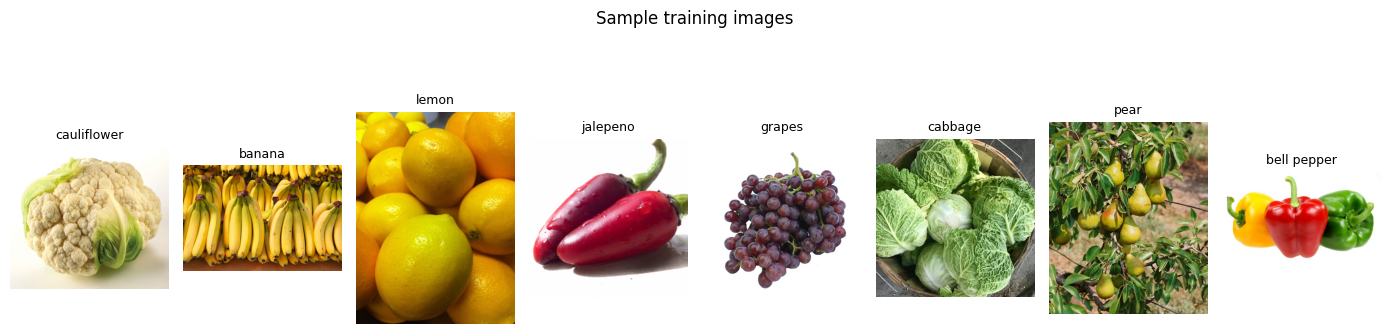

In [4]:
plt.figure(figsize=(14, 4))
for i, c in enumerate(random.sample(classes, min(8, len(classes)))):
    imgs = list((DATA / 'train' / c).glob('*.*'))
    if imgs:
        img = plt.imread(str(imgs[0]))
        plt.subplot(1, 8, i + 1)
        plt.imshow(img)
        plt.title(c, fontsize=9)
        plt.axis('off')
plt.suptitle('Sample training images')
plt.tight_layout()
plt.show()

## Train YOLOv8n-cls

In [5]:
model = YOLO('yolov8n-cls.pt')
model.train(data=str(DATA.resolve()),
    epochs=10, imgsz=224, batch=64, workers=0, cache=False,
    amp=True, device=0, optimizer="AdamW", lr0=0.001, cos_lr=True,
    seed=42, patience=5, plots=False, save=True, val=True,
    project="runs", name="veg_cls", exist_ok=True)
save_dir = Path(model.trainer.save_dir)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset/fruit_and_vegetable, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=veg_cls, nbs=64, nms=None, opset=None, optimize=

## Evaluation on Test Set

In [6]:
metrics = model.val(data=str(DATA.resolve()), split='test')
print(f'Test top-1 accuracy: {metrics.top1:.4f}   Test top-5 accuracy: {metrics.top5:.4f}')

for name in ['results.png', 'confusion_matrix.png']:
    p = save_dir / name
    if p.exists():
        plt.figure(figsize=(14, 9))
        plt.imshow(plt.imread(str(p)))
        plt.title(name)
        plt.axis('off')
        plt.show()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,480,996 parameters, 0 gradients, 3.3 GFLOPs
train: /content/dataset/fruit_and_vegetable/train... found 3115 images in 36/36 classes ✅ 
val: /content/dataset/fruit_and_vegetable/val... found 351 images in 36/36 classes ✅ 
test: /content/dataset/fruit_and_vegetable/test... found 359 images in 36/36 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 161.2±96.1 MB/s, size: 1234.9 KB)
test: Scanning /content/dataset/fruit_and_vegetable/test... 359 images, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 533.2it/s 0.7s
test: New cache created: /content/dataset/fruit_and_vegetable/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 23/23 1.4it/s 16.4s
                   all      0.942      0.994
Speed: 0.1ms preprocess, 0.9ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
Test top-1 accuracy: 0.9415 

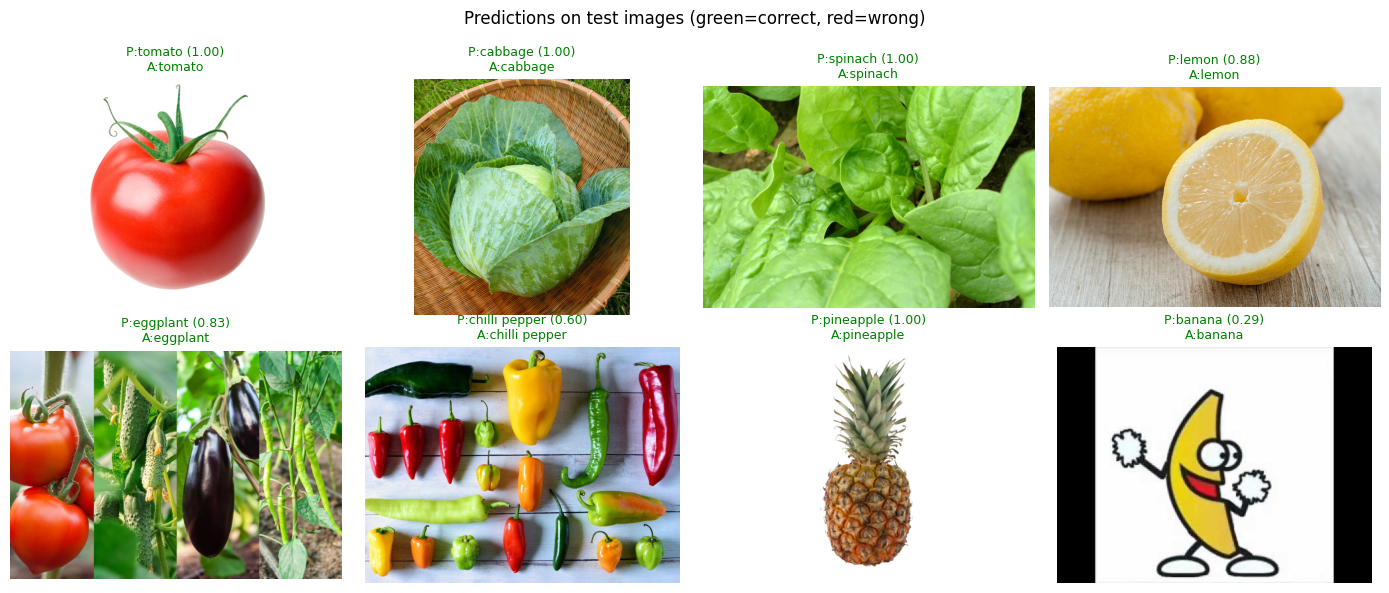

In [8]:
test_images = [p for p in (DATA / 'test').rglob('*.*') if not p.is_dir()]
plt.figure(figsize=(14, 6))
for i, img_path in enumerate(random.sample(test_images, min(8, len(test_images)))):
    r = model.predict(str(img_path), imgsz=224, verbose=False)[0]
    plt.subplot(2, 4, i + 1)
    plt.imshow(r.orig_img[..., ::-1])
    plt.title(f'P:{r.names[r.probs.top1]} ({r.probs.top1conf:.2f})\nA:{img_path.parent.name}', fontsize=9,
              color='green' if r.names[r.probs.top1] == img_path.parent.name else 'red')
    plt.axis('off')
plt.suptitle('Predictions on test images (green=correct, red=wrong)')
plt.tight_layout()
plt.show()

## Save and single-image inference

In [9]:
out_dir = Path('outputs')
out_dir.mkdir(exist_ok=True)
shutil.copy2(save_dir / 'weights' / 'best.pt', out_dir / 'fruits_vegs_yolov8n_cls.pt')
print('Saved:', out_dir / 'fruits_vegs_yolov8n_cls.pt')


def classify_image(path, top_k=3):
    r = model.predict(str(path), imgsz=IMG, verbose=False)[0]
    probs = r.probs
    scores = probs.data.cpu().numpy()
    plt.figure(figsize=(5, 5))
    plt.imshow(r.orig_img[..., ::-1])
    plt.title(f'{r.names[probs.top1]} ({float(probs.top1conf):.2f})')
    plt.axis('off')
    plt.show()
    return {r.names[i]: round(float(scores[i]), 4) for i in probs.top5[:top_k]}

Saved: outputs/fruits_vegs_yolov8n_cls.pt
